In [5]:
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt #Plotting properties
import seaborn as sns #Plotting properties
from sklearn.model_selection import train_test_split #Data testing
from sklearn.linear_model import LogisticRegression #Prediction Model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, r2_score, roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
from sklearn.preprocessing import LabelEncoder #Variable encoding and decoding for XGBoost
import category_encoders as ce
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from skopt import BayesSearchCV
from skopt.space import Integer, Categorical
import time

from statsmodels.genmod.generalized_linear_model import GLM


Estre notebook ha sido creado usando material de la clase [Advanced Methods in Data Analysis](https://github.com/albahnsen/AdvancedMethodsDataAnalysisClass). Agradecimiento especial al profesor [Alejandro Correa Bahnsen](albahnsen.com/)

# 🤔🧠 ¿Por qué estamos aprendiendo sobre ensembling? 

 - ✅ Es un método muy popular para mejorar el rendimiento predictivo de los modelos de machine learning.

 - 🧱 Proporciona la base para comprender modelos más sofisticados. 💡🚀

El **aprendizaje por ensamblaje** (*ensemble learning*) es un tema ampliamente estudiado en la comunidad de *machine learning* 🤖📚. La idea principal detrás de la metodología de *ensemble* es **combinar varios clasificadores base individuales** para obtener un clasificador que supere a cada uno de ellos por separado 💪.

En la actualidad, los métodos de *ensemble* son unas de las técnicas de *machine learning* más **populares y mejor estudiadas** 🏅, y puede notarse que desde 2009 **todos los ganadores de primer y segundo lugar del KDD-Cup** (https://www.sigkdd.org/kddcup/) han utilizado métodos de *ensemble* 🏆. El principio central del *ensemble learning* es **inducir perturbaciones aleatorias en el procedimiento de aprendizaje** 🎲 para producir varios clasificadores base diferentes a partir de un mismo conjunto de entrenamiento, y luego **combinar esos clasificadores base** para hacer la predicción final 🎯.

Para inducir esas permutaciones aleatorias y, por lo tanto, crear los distintos clasificadores base, se han propuesto varios métodos, en particular:

- 🧺 **Bagging**
- 📦 **Pasting**
- 🌲 **Random forests**
- 🧩 **Random patches**

Finalmente, una vez se han entrenado los clasificadores base, estos suelen combinarse usando:

- 🗳️ **Majority voting** (votación por mayoría)
- ⚖️ **Weighted voting** (votación ponderada)
- 🏗️ **Stacking**

---

### ¿Por qué los métodos de *ensemble* suelen funcionar mejor? 🤔

Existen tres razones principales por las cuales los métodos de *ensemble* suelen tener mejor desempeño que los modelos individuales: **estadística, computacional y representacional** 🧠.

1. **Razón estadística** 📈: cuando el conjunto de entrenamiento es muy pequeño, un algoritmo puede encontrar varios modelos “buenos” dentro del espacio de búsqueda que obtienen un rendimiento similar sobre el conjunto de entrenamiento $(\mathcal{S})$. Sin embargo, sin un conjunto de validación, existe el riesgo de escoger el modelo equivocado. Al combinar varios modelos, el *ensemble* reduce este riesgo ✅.

2. **Razón computacional** 🖥️: en general, los algoritmos de aprendizaje dependen de algún tipo de optimización local y pueden quedarse atrapados en un óptimo local. Un *ensemble* puede aliviar este problema haciendo que distintos algoritmos (o el mismo algoritmo con perturbaciones) exploren diferentes regiones del espacio de hipótesis 🔁.

3. **Razón representacional** 🧩: en muchos casos, para un conjunto de datos de tamaño finito, la función verdadera $(f)$ **no puede ser representada por ninguno de los modelos candidatos** de forma individual. Al combinar varios modelos en un *ensemble*, es posible obtener un modelo con **mayor cobertura** dentro del espacio de funciones representables 🌐.


## Ejemplo 🎯

Imaginemos que, en lugar de construir **un solo modelo** para resolver un problema de clasificación binaria, creaste **cinco modelos independientes**, y cada modelo acierta el **70%** de las veces (0.7 de probabilidad de acierto).

Ahora los combinas en un **ensemble** y usas **votación por mayoría** (es decir, te quedas con la clase que más modelos predigan). ¿Qué tan seguido acertaría el ensemble? 🤔

Para que el ensemble acierte, al menos **3 de los 5 modelos** deben acertar (3, 4 o 5 aciertos).

Calculemos la probabilidad:

- ✅ Probabilidad de que acierten exactamente 3 modelos:  
  $( \binom{5}{3} \cdot 0.7^3 \cdot 0.3^2 = 10 \cdot 0.343 \cdot 0.09 \approx 0.3087 )$

- ✅ Probabilidad de que acierten exactamente 4 modelos:  
  $( \binom{5}{4} \cdot 0.7^4 \cdot 0.3 = 5 \cdot 0.2401 \cdot 0.3 \approx 0.36015 )$

- ✅ Probabilidad de que acierten los 5 modelos:  
  $( 0.7^5 \approx 0.16807 )$

Sumamos todas las que tienen mayoría ✔️:

$$
0.3087 + 0.36015 + 0.16807 \approx 0.83692
$$

👉 **El ensemble acertaría aproximadamente el 84% de las veces** 🎉  
(o sea, ¡mejor que cualquiera de los modelos individuales que solo acertaban el 70%!)


In [6]:
import numpy as np

# set a seed for reproducibility
np.random.seed(1234)

# generate 1000 random numbers (between 0 and 1) for each model, representing 1000 observations
mod1 = np.random.rand(1000)
mod2 = np.random.rand(1000)
mod3 = np.random.rand(1000)
mod4 = np.random.rand(1000)
mod5 = np.random.rand(1000)

# each model independently predicts 1 (the "correct response") if random number was at least 0.3
preds1 = np.where(mod1 > 0.3, 1, 0)
preds2 = np.where(mod2 > 0.3, 1, 0)
preds3 = np.where(mod3 > 0.3, 1, 0)
preds4 = np.where(mod4 > 0.3, 1, 0)
preds5 = np.where(mod5 > 0.3, 1, 0)

# print the first 20 predictions from each model
print(preds1[:20])
print(preds2[:20])
print(preds3[:20])
print(preds4[:20])
print(preds5[:20])

[0 1 1 1 1 0 0 1 1 1 1 1 1 1 1 1 1 0 1 1]
[1 1 1 1 1 1 1 0 1 0 0 0 1 1 1 0 1 0 0 0]
[1 1 1 1 0 1 1 0 0 1 1 1 1 1 1 1 1 0 1 1]
[1 1 0 0 0 0 1 1 0 1 1 1 1 1 1 0 1 1 1 0]
[0 0 1 0 0 0 1 0 1 0 0 0 1 1 1 1 1 1 1 1]


In [7]:
# average the predictions and then round to 0 or 1
ensemble_preds = np.round((preds1 + preds2 + preds3 + preds4 + preds5)/5.0).astype(int)

# print the ensemble's first 20 predictions
print(ensemble_preds[:20])

[1 1 1 1 0 0 1 0 1 1 1 1 1 1 1 1 1 0 1 1]


In [8]:
# how accurate was each individual model?
print(preds1.mean())
print(preds2.mean())
print(preds3.mean())
print(preds4.mean())
print(preds5.mean())

0.713
0.665
0.717
0.712
0.687


In [9]:
# how accurate was the ensemble?
print(ensemble_preds.mean())

0.841


Nota: A medida que agregas más modelos al proceso de votación, la probabilidad de error disminuye ✅.

Esto es conocido como [Condorcet's Jury Theorem](http://en.wikipedia.org/wiki/Condorcet%27s_jury_theorem). 🧠🗳️.

## ¿Qué es el ensembling? 🤖

**El aprendizaje por ensamblaje (o "ensembling")** es el proceso de combinar varios modelos predictivos para producir un modelo combinado que sea **más preciso que cualquiera de los modelos individuales**.

- **Regresión:** se toma el promedio de las predicciones.
- **Clasificación:** se toma una votación y se usa la predicción más común, o se toma el promedio de las probabilidades predichas.

Para que el *ensembling* funcione bien, los modelos deben tener las siguientes características:

- **Precisos:** superan al modelo nulo.
- **Independientes:** sus predicciones se generan usando procesos distintos.

**La gran idea:** si tienes un conjunto de modelos que son individualmente imperfectos (pero independientes), los errores “puntuales” que comete cada modelo probablemente **no serán cometidos por los demás**, y por lo tanto esos errores se descartan al promediar o votar entre los modelos. ✅

Existen dos **métodos básicos de ensembling:**

- Hacer manualmente el ensamblaje de tus modelos individuales.
- Usar un modelo que haga el ensamblaje por ti.


### Desempeño teórico de un ensemble 📐

Si asumimos que cada uno de los $(T)$ clasificadores base tiene una probabilidad $(\rho)$ de ser correcto, la probabilidad de que el **ensemble** tome la decisión correcta, asumiendo independencia, y que denotamos por $(P_c)$, puede calcularse usando la distribución binomial:

$$
P_c = \sum_{j > T/2}^{T} \binom{T}{j} \rho^j (1 - \rho)^{T - j}.
$$

Además, se puede mostrar que, si $(T \ge 3)$, entonces:

$$
  \lim_{T \to \infty} P_c =
  \begin{cases}
    1, & \text{si } \rho > 0.5 \\
    0, & \text{si } \rho < 0.5 \\
    0.5, & \text{si } \rho = 0.5
  \end{cases}
$$

lo que lleva a la conclusión de que:

$$
  \rho \ge 0.5 \quad \text{y} \quad T \ge 3 \quad \Rightarrow \quad P_c \ge \rho.
$$


# Parte 2: Manual Ensambling

Qué hace que un ensamble sea bueno?

- Diferentes tipos de **modelos**
- Diferentes combinaciones de **variables**
- Diferente **tuning de parámetros**

![Machine learning flowchart](https://raw.githubusercontent.com/justmarkham/DAT8/master/notebooks/images/crowdflower_ensembling.jpg)

*Machine learning flowchart created by the [winner](https://github.com/ChenglongChen/Kaggle_CrowdFlower) of Kaggle's [CrowdFlower competition](https://www.kaggle.com/c/crowdflower-search-relevance)*

In [10]:
# read in and prepare the vehicle training data
import pandas as pd
url = 'https://raw.githubusercontent.com/albahnsen/PracticalMachineLearningClass/master/datasets/vehicles_train.csv'
train = pd.read_csv(url)
train['vtype'] = train.vtype.map({'car':0, 'truck':1})
# read in and prepare the vehicle testing data
url = 'https://raw.githubusercontent.com/albahnsen/PracticalMachineLearningClass/master/datasets/vehicles_test.csv'
test = pd.read_csv(url)
test['vtype'] = test.vtype.map({'car':0, 'truck':1})

In [11]:
train.shape, test.shape

((14, 5), (3, 5))

In [12]:
train

,price,year,miles,doors,vtype
0,22000,2012,13000,2,0
1,14000,2010,30000,2,0
2,13000,2010,73500,4,0
3,9500,2009,78000,4,0
4,9000,2007,47000,4,0
5,4000,2006,124000,2,0
6,3000,2004,177000,4,0
7,2000,2004,209000,4,1
8,3000,2003,138000,2,0
9,1900,2003,160000,4,0


In [13]:
test

,price,year,miles,doors,vtype
0,3000,2003,130000,4,1
1,6000,2005,82500,4,0
2,12000,2010,60000,2,0


In [14]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

models = {
    'lr':    LinearRegression(),
    'ridge': Ridge(),
    'lasso': Lasso(),
    'dt':    DecisionTreeRegressor(),
    'svm':   SVR(),
}

In [15]:
# Train all the models
X_train = train.iloc[:, 1:]
X_test = test.iloc[:, 1:]
y_train = train.price
y_test = test.price

for model in models.keys():
    models[model].fit(X_train, y_train)

In [16]:
# predict test for each model
y_pred = pd.DataFrame(index=test.index, columns=models.keys())
for model in models.keys():
    y_pred[model] = models[model].predict(X_test)
    

In [17]:
y_pred

,lr,ridge,lasso,dt,svm
0,5909.172251,5092.045616,5901.851176,5000.0,3501.069992
1,7870.639018,7863.300950,7871.279155,5000.0,3504.590160
2,13324.820758,13416.942776,13324.834734,13000.0,3505.847911


In [18]:
# Evaluate each model
from sklearn.metrics import mean_squared_error

for model in models.keys():
    print(model,np.sqrt(mean_squared_error(y_pred[model], y_test)))

lr 2138.3579028745116
ridge 1812.573871781592
lasso 2135.229339595643
dt 1414.213562373095
svm 5119.529962573867


In [19]:
y_pred.mean(axis=1)

0     5080.827807
1     6421.961857
2    11314.489236
dtype: float64

In [20]:
np.sqrt(mean_squared_error(y_pred.mean(axis=1), y_test))

np.float64(1288.1279929165855)

## ⚖️ Comparando el ensembling manual con el enfoque de un solo modelo 

**Ventajas del ensembling manual:**

- 📈 Aumenta la precisión predictiva
- 🟢 Es fácil de empezar a usar

**Desventajas del ensembling manual:**

- 🧐 Disminuye la interpretabilidad
- 🐢 Toma más tiempo entrenar
- ⏱️ Toma más tiempo predecir
- 🛠️ Es más complejo de automatizar y mantener
- ⚖️ Las pequeñas mejoras en precisión pueden no justificar la complejidad añadida


# Parte 3: Bagging
La principal debilidad de los **decision trees** al ser modelos "estáticos" no contienen fuentes aleatorias de información y la variabilidad es mínima. Esto es, parcialmente se debe a **variabilidad alta**, esto significa que diferentes divisiones dentro del árbol, conllevan a diferentes predicciones.

**Bagging** es una propuesta general para reducir la varianza de los métodos de maachine learning, pero es particularmente útil para los árboles de decisión. Bagging es el acrónimo para **bootstrap aggregation**, es decir, agregación de muestras por boostraping.

Pero... qué es **bootstrap sample**? Una muestra aleatoria con reemplazo:

In [21]:
# set a seed for reproducibility
np.random.seed(1)

# create an array of 1 through 20
nums = np.arange(1, 11)
print(nums)

# sample that array 20 times with replacement
print(np.random.choice(a=nums, size=20, replace=True))

[ 1  2  3  4  5  6  7  8  9 10]
[ 6  9 10  6  1  1  2  8  7 10  3  5  6  3  5  3  5  8  8 10]


## **Cómo funciona el bagging para decision trees?**

1. Cree $B$ árboles usando $B$ **bootstrap samples** utilizando el dataset de entrenamiento.
2. Entrene cada árbol con cada una de las muestras de boostraping y genere predicciones.
3. Combine las predicciones a través de algún método:
    - Promedio de las predicciones para **árboles de regresión**
    - Voto (promedio, popular, otro) **árboles de clasificación**

Nota:

- **Cada muestra de boostraping** debe tener el mismo tamaño del dataset original.
- **B** debe ser un valor suficientemente grande, como para que el error se vea "estable".
- Los árboles deben ser **grown deep**, esto siginifica, bajo sesgo/varianza alta.


____

Bagging incrementa el poder predictivo a través de **reducir la varianza**, similar a como validación cruzada (cross-valdiation) reduce la varianza asociada a train/test split (estimando el out-of-sample error) dividiendo muchas veces la muestra para finalmente calcular un accuracy promedio.


In [22]:
# set a seed for reproducibility
np.random.seed(123)

n_samples = train.shape[0]
n_samples

14

In [23]:
n_B = 10

# create ten bootstrap samples (will be used to select rows from the DataFrame)
samples = [np.random.choice(a=n_samples, size=n_samples, replace=True) for _ in range(1, n_B +1 )]
samples

[array([13,  2, 12,  2,  6,  1,  3, 10, 11,  9,  6,  1,  0,  1],
       dtype=int32),
 array([ 9,  0,  0,  9,  3, 13,  4,  0,  0,  4,  1,  7,  3,  2],
       dtype=int32),
 array([ 4,  7,  2,  4,  8, 13,  0,  7,  9,  3, 12, 12,  4,  6],
       dtype=int32),
 array([ 1,  5,  6, 11,  2,  1, 12,  8,  3, 10,  5,  0, 11,  2],
       dtype=int32),
 array([10, 10,  6, 13,  2,  4, 11, 11, 13, 12,  4,  6, 13,  3],
       dtype=int32),
 array([10,  0,  6,  4,  7, 11,  6,  7,  1, 11, 10,  5,  7,  9],
       dtype=int32),
 array([ 2,  4,  8,  1, 12,  2,  1,  1,  3, 12,  5,  9,  0,  8],
       dtype=int32),
 array([11,  1,  6,  3,  3, 11,  5,  9,  7,  9,  2,  3, 11,  3],
       dtype=int32),
 array([ 3,  8,  6,  9,  7,  6,  3,  9,  6, 12,  6, 11,  6,  1],
       dtype=int32),
 array([13, 10,  3,  4,  3,  1, 13,  0,  5,  8, 13,  6, 11,  8],
       dtype=int32)]

In [24]:
# show the rows for the first decision tree
train.iloc[samples[0], :].sort_index()

,price,year,miles,doors,vtype
0,22000,2012,13000,2,0
1,14000,2010,30000,2,0
1,14000,2010,30000,2,0
1,14000,2010,30000,2,0
2,13000,2010,73500,4,0
2,13000,2010,73500,4,0
3,9500,2009,78000,4,0
6,3000,2004,177000,4,0
6,3000,2004,177000,4,0
9,1900,2003,160000,4,0


Cree un árbol de decisión para cada muestra

In [25]:
# grow each tree deep
treereg = DecisionTreeRegressor(max_depth=None, random_state=123)

# DataFrame for storing predicted price from each tree
y_pred = pd.DataFrame(index=test.index, columns=[list(range(n_B))])

# grow one tree for each bootstrap sample and make predictions on testing data
for i, sample in enumerate(samples):
    X_train = train.iloc[sample, 1:]
    y_train = train.iloc[sample, 0]
    treereg.fit(X_train, y_train)
    y_pred[i] = treereg.predict(X_test)

In [26]:
y_pred

,0,1,2,3,4,5,6,7,8,9
0,1300.0,1300.0,3000.0,4000.0,1300.0,4000.0,4000.0,4000.0,3000.0,4000.0
1,5000.0,1300.0,3000.0,5000.0,5000.0,5000.0,4000.0,5000.0,5000.0,5000.0
2,14000.0,13000.0,13000.0,13000.0,13000.0,14000.0,13000.0,13000.0,9500.0,9000.0


Resultados de cada árbol

In [27]:
for i in range(n_B):
    print(i, np.sqrt(mean_squared_error(y_pred[i], y_test)))

0 1621.7274740226856
1 2942.7877939124323
2 1825.7418583505537
3 1000.0
4 1276.7145334803704
5 1414.213562373095
6 1414.213562373095
7 1000.0
8 1554.5631755148024
9 1914.854215512676


In [28]:
y_pred.mean(axis=1)

0     2990.0
1     4330.0
2    12450.0
dtype: float64

In [29]:
np.sqrt(mean_squared_error(y_test, y_pred.mean(axis=1)))

np.float64(998.5823284370031)

## ⚖️ Bagged decision trees usando scikit-learn (con B=500)

La implementación de este tipo de modelos, ya esta creada usando scikit-learn

In [30]:
# define the training and testing sets
X_train = train.iloc[:, 1:]
y_train = train.iloc[:, 0]
X_test = test.iloc[:, 1:]
y_test = test.iloc[:, 0]

In [31]:
X_train, y_train

(    year   miles  doors  vtype
 0   2012   13000      2      0
 1   2010   30000      2      0
 2   2010   73500      4      0
 3   2009   78000      4      0
 4   2007   47000      4      0
 5   2006  124000      2      0
 6   2004  177000      4      0
 7   2004  209000      4      1
 8   2003  138000      2      0
 9   2003  160000      4      0
 10  2003  190000      2      1
 11  2001   62000      4      0
 12  1999  163000      2      1
 13  1997  138000      4      0,
 0     22000
 1     14000
 2     13000
 3      9500
 4      9000
 5      4000
 6      3000
 7      2000
 8      3000
 9      1900
 10     2500
 11     5000
 12     1800
 13     1300
 Name: price, dtype: int64)

In [32]:
X_test, y_test

(   year   miles  doors  vtype
 0  2003  130000      4      1
 1  2005   82500      4      0
 2  2010   60000      2      0,
 0     3000
 1     6000
 2    12000
 Name: price, dtype: int64)

In [33]:
# instruct BaggingRegressor to use DecisionTreeRegressor as the "base estimator"
from sklearn.ensemble import BaggingRegressor
bagreg = BaggingRegressor(DecisionTreeRegressor(), n_estimators=500, 
                          bootstrap=True, oob_score=True, random_state=1)

In [34]:
# fit and predict
bagreg.fit(X_train, y_train)
y_pred = bagreg.predict(X_test)
y_pred

array([ 3335. ,  5419.8, 12956. ])

In [35]:
# calculate RMSE
np.sqrt(mean_squared_error(y_test, y_pred))

np.float64(673.9913550385247)

## 🧐 Estimación del out-of-sample error

Para los modelos creados a través de bagging, el out-of-sample error puede ser estimado sin necesidad de usar **train/test split** o **cross-validation**!

En promedio, each modelo de bagging usa **dos-terceras partes** de todas las observaciones. Para cada modelo, las **observaciones restantes** son llamadas "out-of-bag observations".

In [36]:
# show the first bootstrap sample
samples[0]

array([13,  2, 12,  2,  6,  1,  3, 10, 11,  9,  6,  1,  0,  1],
      dtype=int32)

In [37]:
# show the "in-bag" observations for each sample
for sample in samples:
    print(set(sample))

{np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(6), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13)}
{np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(7), np.int32(9), np.int32(13)}
{np.int32(0), np.int32(2), np.int32(3), np.int32(4), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(12), np.int32(13)}
{np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(5), np.int32(6), np.int32(8), np.int32(10), np.int32(11), np.int32(12)}
{np.int32(2), np.int32(3), np.int32(4), np.int32(6), np.int32(10), np.int32(11), np.int32(12), np.int32(13)}
{np.int32(0), np.int32(1), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(9), np.int32(10), np.int32(11)}
{np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(8), np.int32(9), np.int32(12)}
{np.int32(1), np.int32(2), np.int32(3), np.int32(5), np.int32(6), np.int32(7), np.int32(9), np.int32(11)}
{np.int32(1), np.int32(3), np.int32(6)

In [38]:
# show the "out-of-bag" observations for each sample
for sample in samples:
    print(sorted(set(range(n_samples)) - set(sample)))

[4, 5, 7, 8]
[5, 6, 8, 10, 11, 12]
[1, 5, 10, 11]
[4, 7, 9, 13]
[0, 1, 5, 7, 8, 9]
[2, 3, 8, 12, 13]
[6, 7, 10, 11, 13]
[0, 4, 8, 10, 12, 13]
[0, 2, 4, 5, 10, 13]
[2, 7, 9, 12]


## 🛠️ Cómo calcular el **"out-of-bag error":**

1. Para cada observación en el conjunto **train**, predecir la variable de respuesta $y$ **solamente** con los árboles en los que esa observación estuviera out-of-bag. Promedie esas predicciones (para regresión) o tome el voto (para clasifciación).
2. Compare todas las predicciones con el valor real de la respuesta para calcular el out-of-bag error.

Caundo $B$ es suficientemente grande, el **out-of-bag error** es un estimador de **out-of-sample error**.

In [39]:
# compute the out-of-bag R-squared score (not MSE, unfortunately!) for B=500
bagreg.oob_score_

0.7662607997982768

## 🟢 Estimación del feature importance

Bagging incrementa **capacidad predictiva**, pero disminuye la **interpretabilidad del modelo** porque en ese orden de ideas, se vuelve imposible visualizar cada árbol para entender la importancia de cada variable.

Sin embargo, podemos obtener un resumen en alto nivel del **feature importance** de los modelos dentro del bagging:

- **Bagged regression trees:** Calcular el total que el **MSE** disminuye dadas las divisiones por una variable en particular, luego se promedia este valor a través de todos los árboles calculados.
- **Bagged classification trees:** Calcular el total que el **Gini index** disminuye dadas las divisiones por una variable en particular, luego se promedia este valor a través de todos los árboles calculados.

# Parte 4: Combinación de clasiicadores - Voto mayoritario

Esta es la metodología más común de ensamblaje combinando $T$ diferentes clasificadores base.

Cada clasificador base $M(\mathcal{S}_j)$ es entrenado aplicando el algoritmo $M$ a una sub-muestra aleatoria $\mathcal{S}_j$ del train dataset $\mathcal{S}$.

Para simplicidad de notación definimos $M_j \equiv  M(\mathcal{S}_j)$ for $j=1,\dots,T$, y $\mathcal{M}=\{M_j\}_{j=1}^{T}$ un conjunt de clasificadores base.

Entonces, esto modelos son combinados usando **voto mayoritario** para crear el ensamblaje $H$ como sigue:

  $$
    H(\mathcal{S},\mathcal{M}) = max_{c \in \{0,1\}} \sum_{j=1}^T 
    \mathbf{1}_c(M_j(\mathcal{S})).
  $$


In [40]:
# read in and prepare the churn data
# Download the dataset
import pandas as pd
import numpy as np

url = 'https://raw.githubusercontent.com/albahnsen/PracticalMachineLearningClass/master/datasets/churn.csv'
data = pd.read_csv(url)

# Create X and y

# Select only the numeric features
X = data.iloc[:, [1,2,6,7,8,9,10]].astype(float)
# Convert bools to floats
X = X.join((data.iloc[:, [4,5]] == 'no').astype(float))

y = (data.iloc[:, -1] == 'True.').astype(int)

In [41]:
X.head()

,Account Length,Area Code,VMail Message,Day Mins,Day Calls,Day Charge,Eve Mins,Int'l Plan,VMail Plan
0,128.0,415.0,25.0,265.1,110.0,45.07,197.4,1.0,0.0
1,107.0,415.0,26.0,161.6,123.0,27.47,195.5,1.0,0.0
2,137.0,415.0,0.0,243.4,114.0,41.38,121.2,1.0,1.0
3,84.0,408.0,0.0,299.4,71.0,50.90,61.9,0.0,1.0
4,75.0,415.0,0.0,166.7,113.0,28.34,148.3,0.0,1.0


In [42]:
y.value_counts().to_frame('count').assign(percentage = lambda x: x/x.sum())

,count,percentage
Churn?,,
0,2850,0.855086
1,483,0.144914


In [43]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [44]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((2233, 9), (1100, 9), (2233,), (1100,))

Crearemos 100 árboles de decisión

In [45]:
n_estimators = 100
# set a seed for reproducibility
np.random.seed(123)

n_samples = X_train.shape[0]

# create bootstrap samples (will be used to select rows from the DataFrame)
samples = [np.random.choice(a=n_samples, size=n_samples, replace=True) for _ in range(n_estimators)]

samples[0:2]

[array([1346, 1122, 1766, ..., 1248,  828,  470],
       shape=(2233,), dtype=int32),
 array([  54,  136, 1098, ...,   10,  642,  473],
       shape=(2233,), dtype=int32)]

In [46]:
from sklearn.tree import DecisionTreeClassifier

np.random.seed(123) 
seeds = np.random.randint(1, 10000, size=n_estimators)

trees = {}
for i in range(n_estimators):
    trees[i] = DecisionTreeClassifier(max_features="sqrt", max_depth=None, random_state=seeds[i])
    trees[i].fit(X_train.iloc[samples[i]], y_train.iloc[samples[i]])

In [47]:
# Predict 
y_pred_df = pd.DataFrame(index=X_test.index, columns=list(range(n_estimators)))
for i in range(n_estimators):
    y_pred_df.iloc[:, i] = trees[i].predict(X_test)

y_pred_df.head()

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
438,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
2674,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1345,0,0,0,1,0,0,0,0,0,1,...,0,0,0,1,1,0,0,1,1,0
1957,0,0,0,0,0,0,0,0,0,1,...,1,0,1,0,0,0,0,0,1,0
2148,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,0


In [48]:
y_pred_df.sum(axis=1).sort_values(ascending=False)[:10]

605     100
1078    100
365      99
2536     99
2573     97
3322     97
289      97
3272     97
1736     95
2325     94
dtype: object

In [49]:
y_pred = (y_pred_df.sum(axis=1) >= (n_estimators / 2)).astype(int)
y_pred.value_counts()


0    1016
1      84
Name: count, dtype: int64

In [50]:
from sklearn import metrics
metrics.f1_score(y_pred, y_test)

0.5245901639344263

In [51]:
metrics.accuracy_score(y_pred, y_test)

0.8945454545454545

### Voto mayoritario con Scikit-learn

In [52]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
clf = BaggingClassifier(estimator=DecisionTreeClassifier(max_features=0.8), n_estimators=100, bootstrap=True,
                        random_state=42, n_jobs=-1, oob_score=True)

In [53]:
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
metrics.f1_score(y_pred, y_test), metrics.accuracy_score(y_pred, y_test)

(0.5344129554655871, 0.8954545454545455)

# Parte 5: Combinación de clasificadores - Weighted Voting

La metodología de voto mayoritario le da el mismo peso a cada clasificador sin importar el "performance" de cada uno de ellos. La pregunta es, por qué no tener en cuenta el performance oob para cada clasificador para así lograr ponderar mejor los votos?

Primero, en la metodología original, se realiza una comparación (promedio) entre los votos, pero ahora ponderaremos utilizando pesos llamados $\alpha_j$ para cada clasificador $M_j$ durante la fase de votación.


$$
  f_{wv}(\mathcal{S},\mathcal{M}, \alpha)
  =\max_{c \in \{0,1\}} \sum_{j=1}^T \alpha_j \mathbf{1}_c(M_j(\mathcal{S})),
$$


Dónde $\alpha=\{\alpha_j\}_{j=1}^T$.

El cálculo de cada $\alpha_j$ depende del performance del clasificador $M_j$.


Ese peso $\alpha_j$ se denomina usualmente como el error de no clasificación normalizado $\epsilon$ del clasificador base $M_j$  en el conjunto out-of-bag $\mathcal{S}_j^{oob}=\mathcal{S}-\mathcal{S}_j$
\begin{equation}
  \alpha_j=\frac{1-\epsilon(M_j(\mathcal{S}_j^{oob}))}{\sum_{j_1=1}^T 
  1-\epsilon(M_{j_1}(\mathcal{S}_{j_1}^{oob}))}.
\end{equation}

Seleccionamos cada muestra oob 

In [56]:
samples_oob = []
# show the "out-of-bag" observations for each sample
for sample in samples:
    samples_oob.append(sorted(set(range(n_samples)) - set(sample)))

Estimamos el oob error de cada clasificador

In [57]:
errors = np.zeros(n_estimators)

for i in range(n_estimators):
    y_pred_ = trees[i].predict(X_train.iloc[samples_oob[i]])
    errors[i] = 1 - metrics.accuracy_score(y_train.iloc[samples_oob[i]], y_pred_)

Text(0.5, 1.0, 'OOB error of each tree')

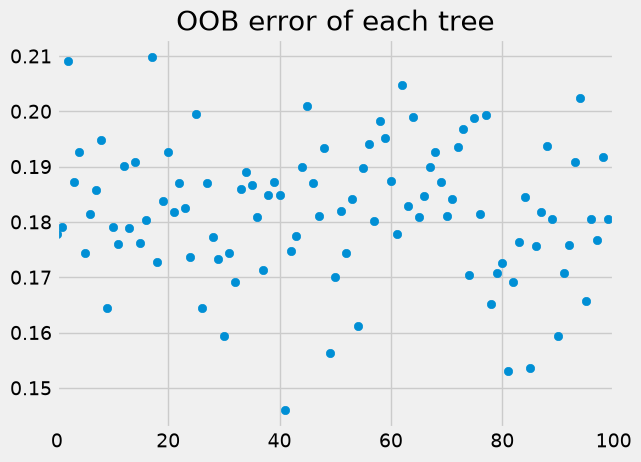

In [58]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

plt.scatter(range(n_estimators), errors)
plt.xlim([0, n_estimators])
plt.title('OOB error of each tree')

Ahora estimamos los pesos $\alpha$, y creamos las ponderaciones correspondientes para darle mayor peso a los modelos con menor error de predicción

In [59]:
alpha = (1 - errors) / (1 - errors).sum()

In [60]:
weighted_sum_1 = ((y_pred_df) * alpha).sum(axis=1)

In [61]:
weighted_sum_1.head(20)

438     0.019994
2674    0.050009
1345    0.350206
1957     0.17023
2148    0.030047
3106      0.0401
1786     0.21979
321     0.059708
3082    0.100208
2240    0.050143
1910    0.180209
2124    0.190141
2351    0.049892
1736    0.950014
879     0.039378
785     0.219648
2684    0.010104
787     0.700482
170     0.220404
1720    0.020166
dtype: object

In [62]:
y_pred = (weighted_sum_1 >= 0.5).astype(int)

metrics.f1_score(y_pred, y_test), metrics.accuracy_score(y_pred, y_test)

(0.5267489711934157, 0.8954545454545455)

### Voto ponderado usando Scikit-learn

In [63]:
clf = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100, bootstrap=True,
                        random_state=42, n_jobs=-1, oob_score=True)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
metrics.f1_score(y_pred, y_test), metrics.accuracy_score(y_pred, y_test)

(0.5241935483870968, 0.8927272727272727)

In [64]:
errors = np.zeros(clf.n_estimators)
y_pred_all_ = np.zeros((X_test.shape[0], clf.n_estimators))

for i in range(clf.n_estimators):
    oob_sample = ~clf.estimators_samples_[i]
    y_pred_ = clf.estimators_[i].predict(X_train.values[oob_sample])
    errors[i] = metrics.accuracy_score(y_pred_, y_train.values[oob_sample])
    y_pred_all_[:, i] = clf.estimators_[i].predict(X_test)
    
alpha = (1 - errors) / (1 - errors).sum()
y_pred = (np.sum(y_pred_all_ * alpha, axis=1) >= 0.5).astype(int)

c:\Users\luisj\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\luisj\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\luisj\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\luisj\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\luisj\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has fe

In [65]:
metrics.f1_score(y_pred, y_test), metrics.accuracy_score(y_pred, y_test)

(0.5418326693227091, 0.8954545454545455)